In [ ]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.linear_model import Ridge, LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import accuracy_score

from pathlib import Path

ROOT = Path(".")

d = np.load("data/decoding_data_757216464.npz")
sp = np.load("data/splits_757216464.npz")

# Start with V1
X = d["X_VISp"]
y = d["y_direction"]
directions = d["directions"]

print("X shape:", X.shape)
print("y shape:", y.shape)
print("directions:", directions)

print("train shape:", sp["train"].shape)
print("val shape:", sp["val"].shape)
print("test shape:", sp["test"].shape)

X shape: (600, 85)
y shape: (600,)
directions: [  0.  45.  90. 135. 180. 225. 270. 315.]
train shape: (20, 360)
val shape: (20, 120)
test shape: (20, 120)


In [3]:
# Block 2: helper for linear Ridge predictions

def nearest_direction(predictions, directions):
    predictions = np.asarray(predictions)

    return np.array([
        directions[np.argmin(np.abs(directions - p))]
        for p in predictions
    ])

In [4]:
# Block 3: candidate ridge strengths

alphas = np.logspace(-3, 3, 13)

print(alphas)

[1.00000000e-03 3.16227766e-03 1.00000000e-02 3.16227766e-02
 1.00000000e-01 3.16227766e-01 1.00000000e+00 3.16227766e+00
 1.00000000e+01 3.16227766e+01 1.00000000e+02 3.16227766e+02
 1.00000000e+03]


In [5]:
# Block 4: linear Ridge decoder across all 20 splits

linear_test_acc = []
linear_best_alpha = []
linear_models = []

for k in range(20):

    train_rows = sp["train"][k]
    val_rows = sp["val"][k]
    test_rows = sp["test"][k]

    X_train, y_train = X[train_rows], y[train_rows]
    X_val, y_val = X[val_rows], y[val_rows]
    X_test, y_test = X[test_rows], y[test_rows]

    best_alpha = None
    best_val_acc = -1

    for alpha in alphas:

        model = make_pipeline(
            StandardScaler(),
            Ridge(alpha=alpha)
        )

        model.fit(X_train, y_train)

        val_pred_continuous = model.predict(X_val)
        val_pred = nearest_direction(val_pred_continuous, directions)

        val_acc = accuracy_score(y_val, val_pred)

        if val_acc > best_val_acc:
            best_val_acc = val_acc
            best_alpha = alpha

    # Refit on train + validation using chosen alpha
    train_val_rows = np.concatenate([train_rows, val_rows])

    final_model = make_pipeline(
        StandardScaler(),
        Ridge(alpha=best_alpha)
    )

    final_model.fit(X[train_val_rows], y[train_val_rows])

    # Test
    test_pred_continuous = final_model.predict(X_test)
    test_pred = nearest_direction(test_pred_continuous, directions)

    test_acc = accuracy_score(y_test, test_pred)

    linear_test_acc.append(test_acc)
    linear_best_alpha.append(best_alpha)
    linear_models.append(final_model)

print("Linear decoder test accuracies:")
print(np.round(linear_test_acc, 3))

print("\nMean linear accuracy:", np.mean(linear_test_acc))

print("\nChosen alpha for each split:")
print(linear_best_alpha)

Linear decoder test accuracies:
[0.158 0.192 0.183 0.192 0.192 0.167 0.2   0.225 0.2   0.183 0.167 0.225
 0.125 0.217 0.183 0.217 0.208 0.217 0.217 0.142]

Mean linear accuracy: 0.19041666666666668

Chosen alpha for each split:
[np.float64(0.001), np.float64(31.622776601683793), np.float64(10.0), np.float64(0.001), np.float64(0.31622776601683794), np.float64(10.0), np.float64(3.1622776601683795), np.float64(0.001), np.float64(0.001), np.float64(3.1622776601683795), np.float64(0.001), np.float64(0.001), np.float64(0.001), np.float64(0.001), np.float64(0.001), np.float64(0.001), np.float64(1.0), np.float64(0.001), np.float64(3.1622776601683795), np.float64(1.0)]


In [6]:
# Block 5: multinomial logistic regression decoder

multi_test_acc = []
multi_best_C = []
multi_models = []

# C is inverse regularization strength in sklearn
Cs = np.logspace(-3, 3, 13)

for k in range(20):

    train_rows = sp["train"][k]
    val_rows = sp["val"][k]
    test_rows = sp["test"][k]

    X_train, y_train = X[train_rows], y[train_rows]
    X_val, y_val = X[val_rows], y[val_rows]
    X_test, y_test = X[test_rows], y[test_rows]

    best_C = None
    best_val_acc = -1

    for C in Cs:

        model = make_pipeline(
            StandardScaler(),
            LogisticRegression(
                C=C,
                penalty="l2",
                solver="lbfgs",
                max_iter=5000
            )
        )

        model.fit(X_train, y_train)

        val_pred = model.predict(X_val)
        val_acc = accuracy_score(y_val, val_pred)

        if val_acc > best_val_acc:
            best_val_acc = val_acc
            best_C = C

    # Refit on train + validation
    train_val_rows = np.concatenate([train_rows, val_rows])

    final_model = make_pipeline(
        StandardScaler(),
        LogisticRegression(
            C=best_C,
            penalty="l2",
            solver="lbfgs",
            max_iter=5000
        )
    )

    final_model.fit(X[train_val_rows], y[train_val_rows])

    # Test
    test_pred = final_model.predict(X_test)
    test_acc = accuracy_score(y_test, test_pred)

    multi_test_acc.append(test_acc)
    multi_best_C.append(best_C)
    multi_models.append(final_model)

print("Multinomial test accuracies:")
print(np.round(multi_test_acc, 3))

print("\nMean multinomial accuracy:", np.mean(multi_test_acc))

print("\nChosen C for each split:")
print(multi_best_C)

Multinomial test accuracies:
[0.85  0.808 0.875 0.775 0.758 0.808 0.808 0.808 0.842 0.892 0.875 0.708
 0.833 0.825 0.792 0.825 0.808 0.858 0.867 0.758]

Mean multinomial accuracy: 0.81875

Chosen C for each split:
[np.float64(0.31622776601683794), np.float64(0.31622776601683794), np.float64(0.1), np.float64(0.01), np.float64(0.03162277660168379), np.float64(0.1), np.float64(0.31622776601683794), np.float64(316.22776601683796), np.float64(1000.0), np.float64(0.1), np.float64(0.1), np.float64(0.0031622776601683794), np.float64(0.01), np.float64(0.1), np.float64(1.0), np.float64(0.03162277660168379), np.float64(0.1), np.float64(0.1), np.float64(0.31622776601683794), np.float64(316.22776601683796)]


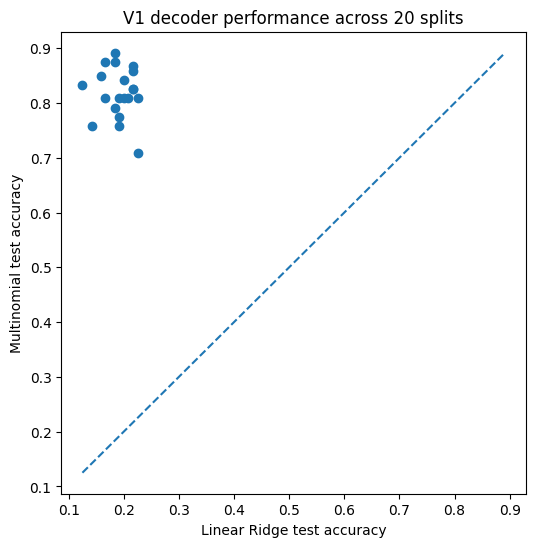

In [7]:
# Block 6: scatter plot comparison

linear_test_acc = np.array(linear_test_acc)
multi_test_acc = np.array(multi_test_acc)

plt.figure(figsize=(6, 6))

plt.scatter(linear_test_acc, multi_test_acc)

low = min(linear_test_acc.min(), multi_test_acc.min())
high = max(linear_test_acc.max(), multi_test_acc.max())

plt.plot([low, high], [low, high], "--")

plt.xlabel("Linear Ridge test accuracy")
plt.ylabel("Multinomial test accuracy")
plt.title("V1 decoder performance across 20 splits")

plt.show()

Each point represents the performance of both models on the same test split: linear accuracy is on the x-axis and multinomial accuracy is on the y-axis. Since all points lie above the diagonal, multinomial regression outperformed linear regression on all 20 splits.

In [8]:
# Block 7: summary

results = pd.DataFrame({
    "split": np.arange(20),
    "linear_accuracy": linear_test_acc,
    "multinomial_accuracy": multi_test_acc,
    "difference": multi_test_acc - linear_test_acc
})

display(results)

print("Mean linear accuracy:", linear_test_acc.mean())
print("Mean multinomial accuracy:", multi_test_acc.mean())
print("Mean difference:", (multi_test_acc - linear_test_acc).mean())

,split,linear_accuracy,multinomial_accuracy,difference
0,0,0.158333,0.850000,0.691667
1,1,0.191667,0.808333,0.616667
2,2,0.183333,0.875000,0.691667
3,3,0.191667,0.775000,0.583333
4,4,0.191667,0.758333,0.566667
5,5,0.166667,0.808333,0.641667
6,6,0.200000,0.808333,0.608333
7,7,0.225000,0.808333,0.583333
8,8,0.200000,0.841667,0.641667
9,9,0.183333,0.891667,0.708333


Mean linear accuracy: 0.19041666666666668
Mean multinomial accuracy: 0.81875
Mean difference: 0.6283333333333334


In [9]:
# Block 8: statistical comparison of the two decoders

from scipy.stats import wilcoxon

differences = multi_test_acc - linear_test_acc

stat, p_value = wilcoxon(differences)

print("Mean linear accuracy:", linear_test_acc.mean())
print("Mean multinomial accuracy:", multi_test_acc.mean())
print("Mean difference:", differences.mean())

print("\nWilcoxon signed-rank test")
print("Statistic:", stat)
print("p-value:", p_value)

print("\nMultinomial better on",
      np.sum(differences > 0),
      "out of",
      len(differences),
      "splits")

Mean linear accuracy: 0.19041666666666668
Mean multinomial accuracy: 0.81875
Mean difference: 0.6283333333333334

Wilcoxon signed-rank test
Statistic: 0.0
p-value: 1.9073486328125e-06

Multinomial better on 20 out of 20 splits


The multinomial decoder significantly outperformed the linear Ridge decoder across all 20 matched data splits. Mean test accuracy was 81.9% for multinomial regression versus 19.0% for linear Ridge regression. The multinomial model performed better on 20/20 splits (Wilcoxon signed-rank test, p = 1.9 × 10⁻⁶).

The multinomial model is better suited to this task because it treats the 8 grating directions as separate classes, while standard linear regression treats direction as a continuous number. Since direction is circular, values like 0° and 315° are actually close physically but look very far apart numerically to a standard linear model.

In [11]:
# Block 9: preferred direction of each V1 unit

preferred_direction = []

for unit in range(X.shape[1]):
    mean_rates = []

    for direction in directions:
        mean_rates.append(
            X[y == direction, unit].mean()
        )

    preferred_direction.append(
        directions[np.argmax(mean_rates)]
    )

preferred_direction = np.array(preferred_direction)

print("Preferred directions of first 20 units:")
print(preferred_direction[:20])

Preferred directions of first 20 units:
[ 90.  90.   0. 180. 225.   0.  90.  90. 180. 180. 270. 270.   0.  90.
  90.  90.  90. 180. 315. 180.]


In [12]:
# Block 10: average multinomial weights across splits

all_multi_weights = []

for model in multi_models:
    # LogisticRegression is the second step of the pipeline
    logistic = model.named_steps["logisticregression"]

    # shape = 8 directions x 85 neurons
    all_multi_weights.append(logistic.coef_)

all_multi_weights = np.array(all_multi_weights)

# average across 20 splits
mean_multi_weights = all_multi_weights.mean(axis=0)

print("Weight matrix shape:", mean_multi_weights.shape)

Weight matrix shape: (8, 85)


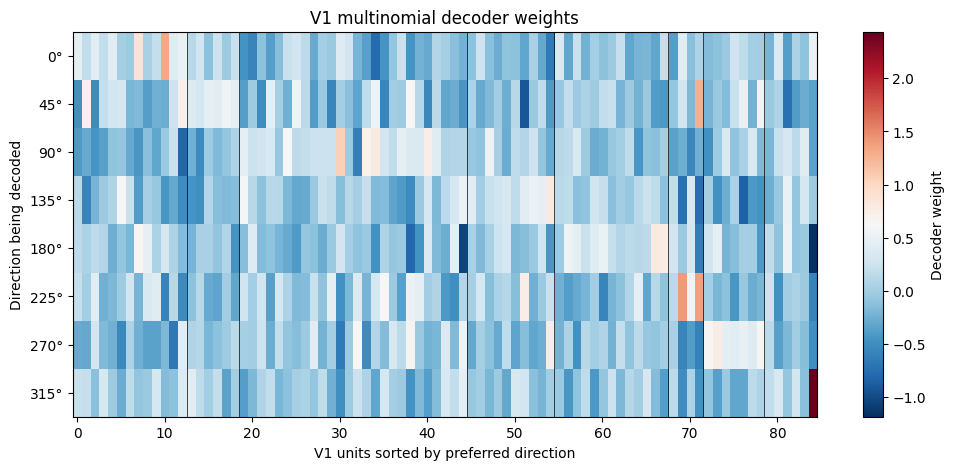

In [13]:
# Block 11: multinomial weight heatmap sorted by preferred direction

sort_idx = np.argsort(preferred_direction)

sorted_pref = preferred_direction[sort_idx]
sorted_weights = mean_multi_weights[:, sort_idx]

plt.figure(figsize=(12, 5))

plt.imshow(
    sorted_weights,
    aspect="auto",
    cmap="RdBu_r"
)

plt.colorbar(label="Decoder weight")

plt.yticks(
    np.arange(len(directions)),
    [f"{int(d)}°" for d in directions]
)

plt.xlabel("V1 units sorted by preferred direction")
plt.ylabel("Direction being decoded")
plt.title("V1 multinomial decoder weights")

# mark where preferred-direction groups change
for i in range(1, len(sorted_pref)):
    if sorted_pref[i] != sorted_pref[i - 1]:
        plt.axvline(i - 0.5, color="black", linewidth=0.5)

plt.show()

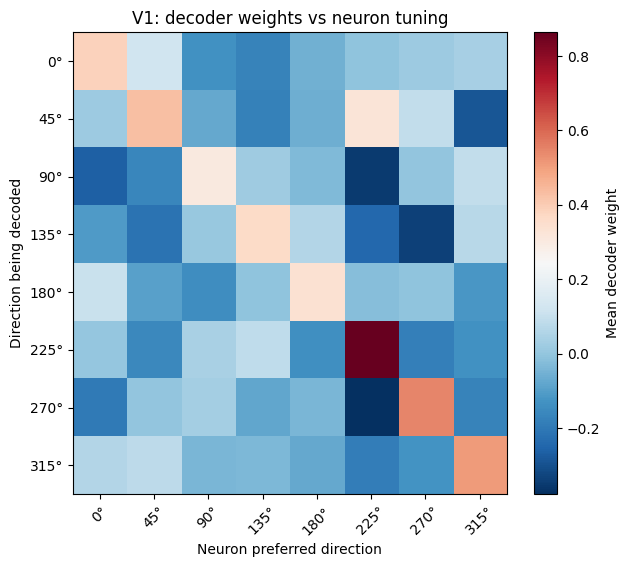

In [14]:
# Block 12: average decoder weight by neuron's preferred direction

weight_by_preference = np.zeros(
    (len(directions), len(directions))
)

for j, pref in enumerate(directions):
    units_with_pref = preferred_direction == pref

    weight_by_preference[:, j] = (
        mean_multi_weights[:, units_with_pref].mean(axis=1)
    )

plt.figure(figsize=(7, 6))

plt.imshow(
    weight_by_preference,
    cmap="RdBu_r",
    aspect="auto"
)

plt.colorbar(label="Mean decoder weight")

plt.xticks(
    np.arange(len(directions)),
    [f"{int(d)}°" for d in directions],
    rotation=45
)

plt.yticks(
    np.arange(len(directions)),
    [f"{int(d)}°" for d in directions]
)

plt.xlabel("Neuron preferred direction")
plt.ylabel("Direction being decoded")
plt.title("V1: decoder weights vs neuron tuning")

plt.show()

Decoder weights align with neural tuning: neurons tend to receive the largest positive weights for the same grating directions they prefer, showing that the decoder uses biologically meaningful tuning information.

LM shape: (600, 53)
Mean LM linear accuracy: 0.13208333333333336
Mean LM multinomial accuracy: 0.6775
Mean difference: 0.5454166666666667
Wilcoxon p-value: 1.9073486328125e-06
Multinomial better on 20 out of 20 splits


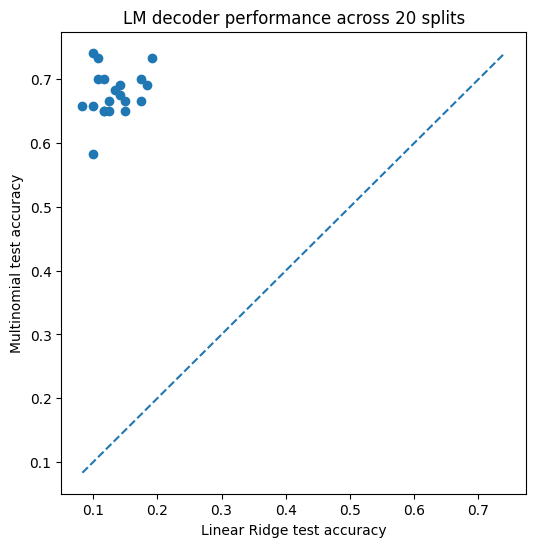

In [15]:
# LM ANALYSIS: linear Ridge + multinomial + scatter + stats

X_LM = d["X_VISl"]
y = d["y_direction"]

print("LM shape:", X_LM.shape)

linear_test_acc_LM = []
multi_test_acc_LM = []
linear_models_LM = []
multi_models_LM = []

for k in range(20):
    train_rows = sp["train"][k]
    val_rows = sp["val"][k]
    test_rows = sp["test"][k]

    X_train, y_train = X_LM[train_rows], y[train_rows]
    X_val, y_val = X_LM[val_rows], y[val_rows]
    X_test, y_test = X_LM[test_rows], y[test_rows]

    # -----------------
    # Linear Ridge
    # -----------------
    best_alpha = None
    best_val_acc = -1

    for alpha in alphas:
        model = make_pipeline(
            StandardScaler(),
            Ridge(alpha=alpha)
        )
        model.fit(X_train, y_train)

        val_pred = nearest_direction(model.predict(X_val), directions)
        val_acc = accuracy_score(y_val, val_pred)

        if val_acc > best_val_acc:
            best_val_acc = val_acc
            best_alpha = alpha

    train_val_rows = np.concatenate([train_rows, val_rows])

    linear_model = make_pipeline(
        StandardScaler(),
        Ridge(alpha=best_alpha)
    )
    linear_model.fit(X_LM[train_val_rows], y[train_val_rows])

    linear_pred = nearest_direction(
        linear_model.predict(X_test),
        directions
    )

    linear_test_acc_LM.append(
        accuracy_score(y_test, linear_pred)
    )
    linear_models_LM.append(linear_model)

    # -----------------
    # Multinomial
    # -----------------
    best_C = None
    best_val_acc = -1

    for C in Cs:
        model = make_pipeline(
            StandardScaler(),
            LogisticRegression(
                C=C,
                penalty="l2",
                solver="lbfgs",
                max_iter=5000
            )
        )
        model.fit(X_train, y_train)

        val_pred = model.predict(X_val)
        val_acc = accuracy_score(y_val, val_pred)

        if val_acc > best_val_acc:
            best_val_acc = val_acc
            best_C = C

    multi_model = make_pipeline(
        StandardScaler(),
        LogisticRegression(
            C=best_C,
            penalty="l2",
            solver="lbfgs",
            max_iter=5000
        )
    )
    multi_model.fit(X_LM[train_val_rows], y[train_val_rows])

    multi_pred = multi_model.predict(X_test)

    multi_test_acc_LM.append(
        accuracy_score(y_test, multi_pred)
    )
    multi_models_LM.append(multi_model)

# Convert to arrays
linear_test_acc_LM = np.array(linear_test_acc_LM)
multi_test_acc_LM = np.array(multi_test_acc_LM)

# Summary
print("Mean LM linear accuracy:", linear_test_acc_LM.mean())
print("Mean LM multinomial accuracy:", multi_test_acc_LM.mean())

differences_LM = multi_test_acc_LM - linear_test_acc_LM

stat_LM, p_value_LM = wilcoxon(differences_LM)

print("Mean difference:", differences_LM.mean())
print("Wilcoxon p-value:", p_value_LM)
print(
    "Multinomial better on",
    np.sum(differences_LM > 0),
    "out of",
    len(differences_LM),
    "splits"
)

# Scatterplot
plt.figure(figsize=(6, 6))
plt.scatter(linear_test_acc_LM, multi_test_acc_LM)

low = min(linear_test_acc_LM.min(), multi_test_acc_LM.min())
high = max(linear_test_acc_LM.max(), multi_test_acc_LM.max())

plt.plot([low, high], [low, high], "--")

plt.xlabel("Linear Ridge test accuracy")
plt.ylabel("Multinomial test accuracy")
plt.title("LM decoder performance across 20 splits")

plt.show()

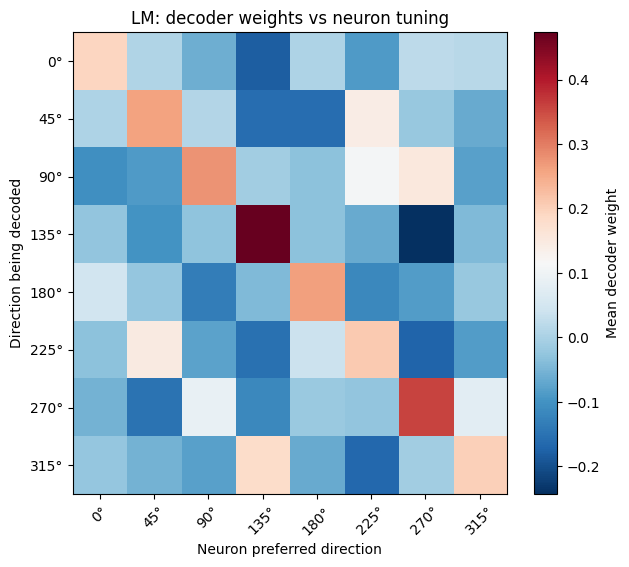

In [16]:
# LM WEIGHT INTERPRETATION

# Preferred direction of each LM neuron
preferred_direction_LM = []

for unit in range(X_LM.shape[1]):
    mean_rates = []

    for direction in directions:
        mean_rates.append(
            X_LM[y == direction, unit].mean()
        )

    preferred_direction_LM.append(
        directions[np.argmax(mean_rates)]
    )

preferred_direction_LM = np.array(preferred_direction_LM)

# Average multinomial weights across the 20 splits
all_multi_weights_LM = []

for model in multi_models_LM:
    logistic = model.named_steps["logisticregression"]
    all_multi_weights_LM.append(logistic.coef_)

mean_multi_weights_LM = np.mean(
    all_multi_weights_LM,
    axis=0
)

# Average weights by preferred direction
weight_by_preference_LM = np.zeros(
    (len(directions), len(directions))
)

for j, pref in enumerate(directions):
    units_with_pref = preferred_direction_LM == pref

    weight_by_preference_LM[:, j] = (
        mean_multi_weights_LM[:, units_with_pref]
        .mean(axis=1)
    )

# Plot
plt.figure(figsize=(7, 6))

plt.imshow(
    weight_by_preference_LM,
    cmap="RdBu_r",
    aspect="auto"
)

plt.colorbar(label="Mean decoder weight")

plt.xticks(
    np.arange(len(directions)),
    [f"{int(d)}°" for d in directions],
    rotation=45
)

plt.yticks(
    np.arange(len(directions)),
    [f"{int(d)}°" for d in directions]
)

plt.xlabel("Neuron preferred direction")
plt.ylabel("Direction being decoded")
plt.title("LM: decoder weights vs neuron tuning")

plt.show()

In [17]:
# Compare V1 vs LM multinomial decoder accuracy

from scipy.stats import wilcoxon

v1_multi = np.array(multi_test_acc)
lm_multi = np.array(multi_test_acc_LM)

difference_region = v1_multi - lm_multi

stat_region, p_region = wilcoxon(difference_region)

print("Mean V1 multinomial accuracy:", v1_multi.mean())
print("Mean LM multinomial accuracy:", lm_multi.mean())
print("Mean V1 - LM difference:", difference_region.mean())

print("\nWilcoxon signed-rank test")
print("Statistic:", stat_region)
print("p-value:", p_region)

print("\nV1 better on",
      np.sum(difference_region > 0),
      "out of",
      len(difference_region),
      "splits")

Mean V1 multinomial accuracy: 0.81875
Mean LM multinomial accuracy: 0.6775
Mean V1 - LM difference: 0.14125000000000001

Wilcoxon signed-rank test
Statistic: 0.0
p-value: 1.9073486328125e-06

V1 better on 20 out of 20 splits


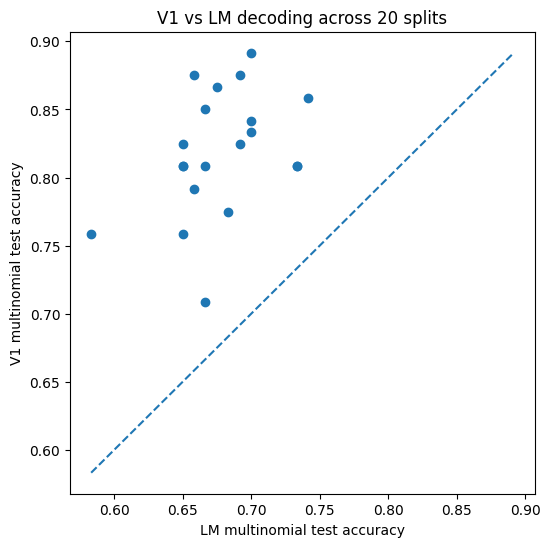

In [18]:
# V1 vs LM multinomial performance

plt.figure(figsize=(6, 6))

plt.scatter(lm_multi, v1_multi)

low = min(lm_multi.min(), v1_multi.min())
high = max(lm_multi.max(), v1_multi.max())

plt.plot([low, high], [low, high], "--")

plt.xlabel("LM multinomial test accuracy")
plt.ylabel("V1 multinomial test accuracy")
plt.title("V1 vs LM decoding across 20 splits")

plt.show()